**Imports and Model Initialization**

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from lif.model import LIFNeuron

# Create the output directory for figures if it does not exist yet
os.makedirs("../figures", exist_ok=True)

# Initialize the LIF neuron with default biophysical parameters
# v_rest: -70 mV, v_reset: -65 mV, v_thresh: -50 mV, tau_m: 10 ms, r_m: 10 MOhm
neuron = LIFNeuron(v_rest=-70.0, v_reset=-65.0, v_thresh=-50.0, tau_m=10.0, r_m=10.0)

**Ramp Current Simulation**

In [2]:
# Configure time grid (400 ms duration with 0.1 ms step size)
dt = 0.1
t_max = 400.0
t = np.arange(0, t_max, dt)

# Generate a linear ramp input current from 0.0 nA to 5.0 nA
# Note: Theoretical rheobase current for these parameters is 2.0 nA
i_inj = np.linspace(0.0, 5.0, len(t))

# Run the simulation
v, spikes = neuron.simulate(i_inj, dt)

# Print summary metrics to verify firing acceleration
print(f"Total spikes fired: {len(spikes)}")
print(f"First spike at: {spikes[0]:.1f} ms | Last ISI: {np.diff(spikes)[-1]:.2f} ms")

Total spikes fired: 34
First spike at: 170.0 ms | Last ISI: 4.20 ms


**Visualization**

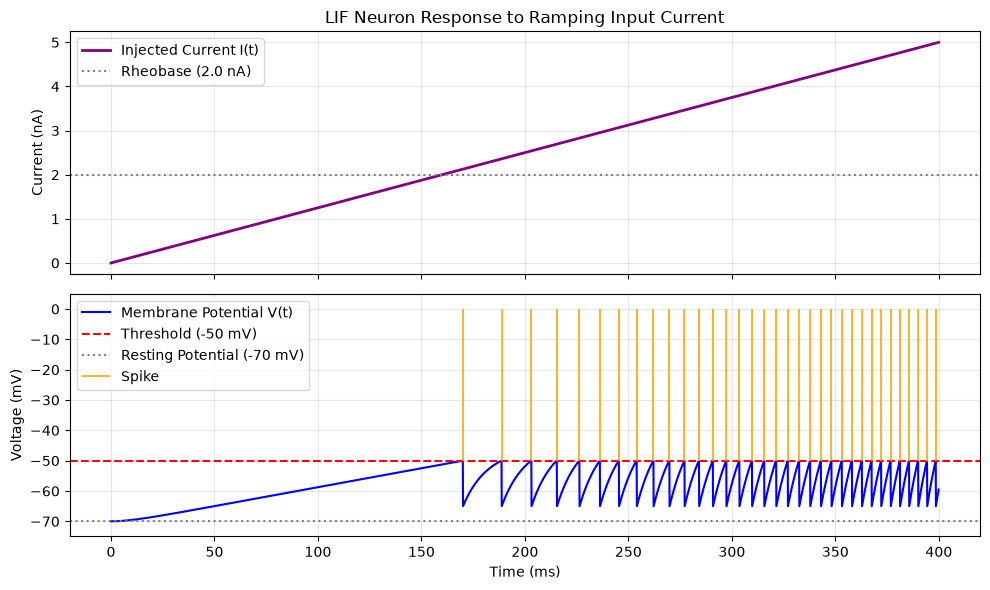

In [3]:
# Set up a two-panel figure sharing the time (x) axis
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# Top Panel: Injected Current I(t)
ax1.plot(t, i_inj, color="purple", linewidth=2, label="Injected Current I(t)")
ax1.axhline(2.0, color="gray", linestyle=":", label="Rheobase (2.0 nA)")
ax1.set_ylabel("Current (nA)")
ax1.set_title("LIF Neuron Response to Ramping Input Current")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

# Bottom Panel: Membrane Potential V(t) and Action Potentials
ax2.plot(t, v, color="b", label="Membrane Potential V(t)")
ax2.axhline(
    neuron.v_thresh,
    color="r",
    linestyle="--",
    label=f"Threshold ({neuron.v_thresh:.0f} mV)",
)
ax2.axhline(
    neuron.v_rest,
    color="gray",
    linestyle=":",
    label=f"Resting Potential ({neuron.v_rest:.0f} mV)",
)

# Draw vertical markers above the threshold for each recorded spike timestamp
ax2.vlines(spikes, neuron.v_thresh, 0, color="orange", linewidth=1.2, label="Spike")

ax2.set_ylabel("Voltage (mV)")
ax2.set_xlabel("Time (ms)")
ax2.set_ylim(-75, 5)
ax2.grid(True, alpha=0.3)
ax2.legend(loc="upper left")

# Adjust spacing and export high-resolution figure for README documentation
plt.tight_layout()
fig.savefig("../figures/ramp_response.png", dpi=150)
plt.show()